In [ ]:
import os
import os.path as op

import matplotlib.pyplot as plt

import holoviews as hv
from holoviews import dim, opts
import pandas as pd

import hnn_core
from hnn_core.params import _short_name

from hnn_core import human_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'

# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text


In [2]:
exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')

## Handtune

In [3]:

prox1_weights_ampa = {'L2_basket': 0.02,
                        'L2_pyramidal': 0.07,
                        'L5_basket': 0.36,
                        'L5_pyramidal': 0.02}
prox1_weights_nmda = {'L2_basket': 0.0002,
                        'L2_pyramidal': 0.005,
                        'L5_basket': 0.04,
                        'L5_pyramidal': 0.002}

dist_weights_ampa = {'L2_basket': 0.0034,
                    'L2_pyramidal': 0.046,
                    'L5_pyramidal': 0.4}
dist_weights_nmda = {'L2_basket': 0.003,
                    'L2_pyramidal': 0.023,
                    'L5_pyramidal': 0.5}

prox2_weights_ampa = {'L2_basket': 0.007,
                        'L2_pyramidal': 0.031,
                        'L5_basket': 0.0028,
                        'L5_pyramidal': 0.649}
prox2_weights_nmda = {'L2_basket': 0.00941,
                    'L2_pyramidal': 0.26,
                    'L5_basket': 0.003,
                    'L5_pyramidal': 0.7}



In [4]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 10

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Applying calcium model baseline correction


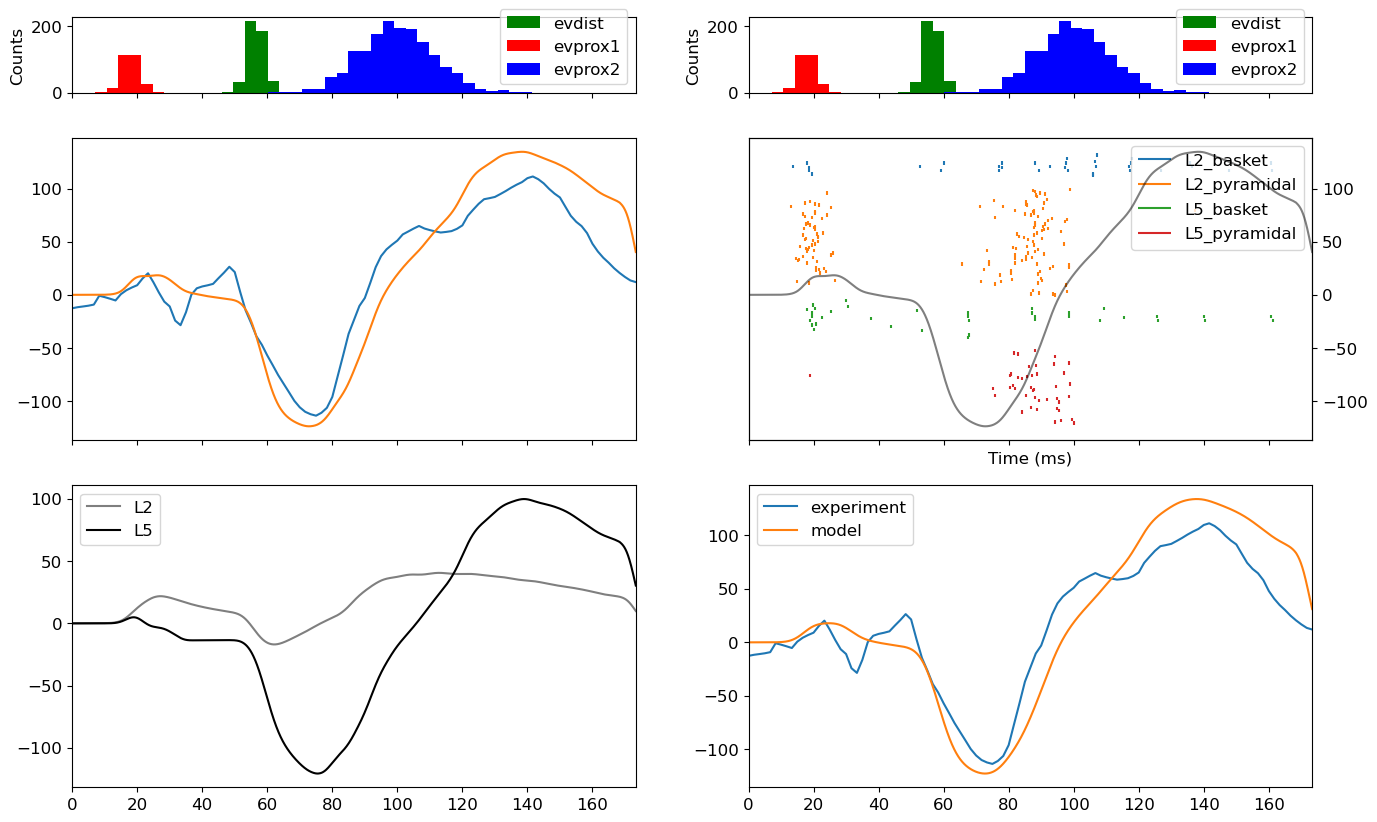

In [ ]:
net_init = human_ET_model()

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net_init.add_evoked_drive('evprox1',
                        mu=18.,
                        sigma=2.5,
                        numspikes=1,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init.add_evoked_drive('evdist',
                        mu=56.5,
                        sigma=2.5,
                        numspikes=2,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net_init.add_evoked_drive('evprox2',
                    mu=100,
                    sigma=11,
                    numspikes=6,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)
init_dpl = simulate_dipole(net_init, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

init_dpl.scale(scale_factor).smooth(smooth_window_len)


fig, ax = plt.subplots(3,2,figsize=(16,10), height_ratios=[0.25,1,1], sharex=True)

net_init.cell_response.plot_spikes_hist(ax=ax[0,0], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)
net_init.cell_response.plot_spikes_hist(ax=ax[0,1], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)


ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='model')

net_init.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
ax2 = ax[1,1].twinx()
ax2.plot(init_dpl.times,init_dpl.data['agg'],color='k', alpha=0.5)

ax[2,0].plot(init_dpl.times,init_dpl.data['L2'], label='L2', color='k', alpha=0.5)
ax[2,0].plot(init_dpl.times,init_dpl.data['L5'], label='L5', color='k')
ax[2,0].legend()

ax[2,1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

smooth_dpl = init_dpl.smooth(smooth_window_len)
ax[2,1].plot(smooth_dpl.times,smooth_dpl.data['agg'], label='model')
ax[2,1].legend()


fig.savefig(os.path.join(pathfig,'initial_dpl.png'))

In [6]:
from hnn_core.dipole import _rmse

init_rmse = _rmse(init_dpl, exp_dpl,tstart=0,tstop=1000)
init_rmse

np.float64(29.199880433622603)

## Import optimized parameters (after two rounds of optimization)

In [7]:
from optimize_drives_slurm import set_params, set_params_time
import pickle

with open('optim_time.pkl', 'rb') as file:
        optim = pickle.load(file)

with open('dpl_time.pkl', 'rb') as file:
        dpl_opt = pickle.load(file)

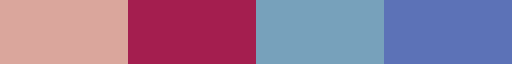

In [ ]:
from cmcrameri import cm
import matplotlib
step_cm = int(len(cm.hawaiiS.colors) / 19)


col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
cmap

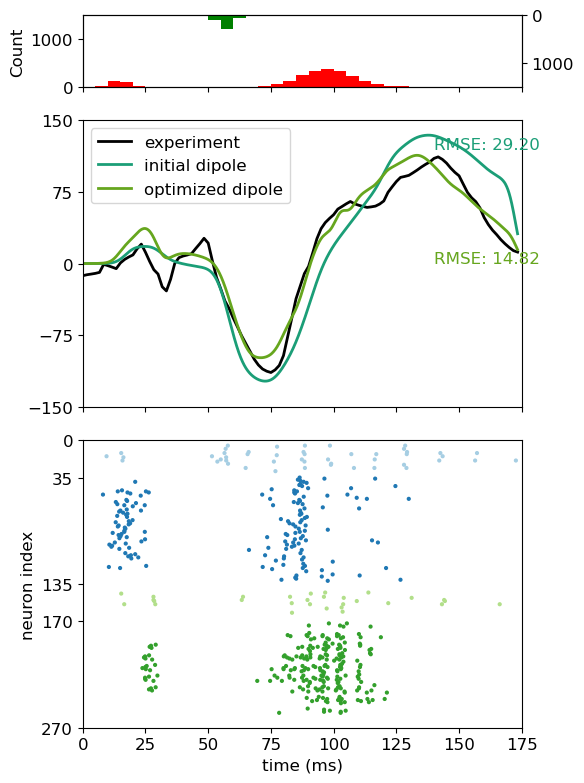

In [10]:
fig, ax = plt.subplots(3,1,figsize=(6,8), height_ratios=[0.25,1,1], sharex=True)

bins = np.arange(0, tstop, 5)  # histogram bins

# proximal and distal histogram
spike_prox1 = np.array(optim.net_.cell_response.spike_times_by_type['prox1']).reshape(-1,1)
spike_dist = np.array(optim.net_.cell_response.spike_times_by_type['dist']).reshape(-1,1)
spike_prox2 = np.array(optim.net_.cell_response.spike_times_by_type['prox2']).reshape(-1,1)

ax[0].hist(spike_prox1, bins, color='r')
ax[0].set_ylim([0, 1500])
ax[0].set_ylabel('Count')
ax[0].hist(spike_prox2, bins, color='r')

ax1tw = ax[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 1500])
ax1tw.invert_yaxis()


ax[1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
ax[1].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized dipole', color=col_lines[-1], linewidth=2)
ax[1].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1].set_ylim([-150, 150])
ax[1].set_yticks([-150, -75, 0, 75, 150])
ax[1].text(140, 0.5, 'RMSE: %.2f' % _rmse(dpl_opt, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[-1])
ax[1].legend()

# spiking
I = np.array(optim.net_.cell_response.spike_gids[0]) <270
gids = np.array(optim.net_.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(optim.net_.cell_response.spike_times).reshape(-1,)[I]
cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

colors = [assign_color(gid) for gid in gids]

ax[2].scatter(times, gids, s=4, alpha=1., c=colors)
ax[2].set_ylabel('neuron index')
ax[2].set_xlim([0, 175])
ax[2].set_xlabel('time (ms)')
ax[2].set_ylim([0, 270])
ax[2].set_yticks([0, 35, 135, 170, 270])
ax[2].invert_yaxis()
ax[2].set_xticks(np.arange(0, 176, 25))
ax[2].set_xlim((0, 175))

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'optimized_dpl.png'))
fig.savefig(os.path.join(pathfig,'optimized_dpl.pdf'), dpi=300)



In [ ]:
# handtune a little bit
net_hand = human_ET_model()
net_hand.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-50,2200,150)))
electrode_pos = [(130, 130, dep) for dep in depths]
net_hand.add_electrode_array('probe1', electrode_pos, method='lsa')

prox1_weights_ampa = optim.net_.external_drives['prox1']['weights_ampa']
prox1_weights_nmda = optim.net_.external_drives['prox1']['weights_nmda']

net_hand.add_evoked_drive('prox1',
                        mu = optim.net_.external_drives['prox1']['dynamics']['mu'],
                        sigma = optim.net_.external_drives['prox1']['dynamics']['sigma'],
                        numspikes = optim.net_.external_drives['prox1']['dynamics']['numspikes'],
                        location = 'proximal',
                        weights_ampa = prox1_weights_ampa,
                        weights_nmda = prox1_weights_nmda,
                        synaptic_delays = synaptic_delays_p, event_seed=544)
# Distal

dist_weights_ampa = {'L2_basket': 0.0015856138634223072,
                    'L2_pyramidal': 0.002,
                    'L5_pyramidal': 1.}
dist_weights_nmda = {'L2_basket': 0.09312719515251287,
                    'L2_pyramidal': 0.002,
                    'L5_pyramidal': .6}

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
net_hand.add_evoked_drive('dist',
                        mu = 55,
                        sigma = optim.net_.external_drives['dist']['dynamics']['sigma'],
                        numspikes = 2,
                        location = 'distal',
                        weights_ampa = dist_weights_ampa,
                        weights_nmda = dist_weights_nmda,
                        synaptic_delays = synaptic_delays_d, event_seed=544)

# Proximal 2
prox2_weights_ampa = {'L2_basket': 0.006622737231283097,
                        'L2_pyramidal': 0.750791266899394,
                        'L5_basket': 0.02229356628634976,
                        'L5_pyramidal': 0.12744892823619833}
prox2_weights_nmda = {'L2_basket': 0.012973495518022455,
                    'L2_pyramidal': 0.022802318835492184,
                    'L5_basket': 0.00422401301129021,
                    'L5_pyramidal': 0.23612697575815428}

net_hand.add_evoked_drive('prox2',
                        mu = 91.5,
                        sigma = 5.5,
                        numspikes = 13,
                        location = 'proximal',
                        weights_ampa = prox2_weights_ampa,
                        weights_nmda = prox2_weights_nmda,
                        synaptic_delays = synaptic_delays_p, event_seed=544)

# Simulate the optimized model
tstop = exp_dpl.times[-1]
smooth_window_len = 10

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    hand_dpl = simulate_dipole(net_hand, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

hand_dpl.scale(scale_factor).smooth(smooth_window_len)

hand_rmse = _rmse(hand_dpl, exp_dpl,tstart=0,tstop=1000)




MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

In [12]:
from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d

contact_labels, delta = _get_laminar_z_coords(net_hand.rec_arrays['probe1'][0].positions)
new_lim = contact_labels[0:len(contact_labels):2]/1000


In [126]:
with open('net_handtuned.pkl', 'wb') as file:
        pickle.dump(net_hand, file)

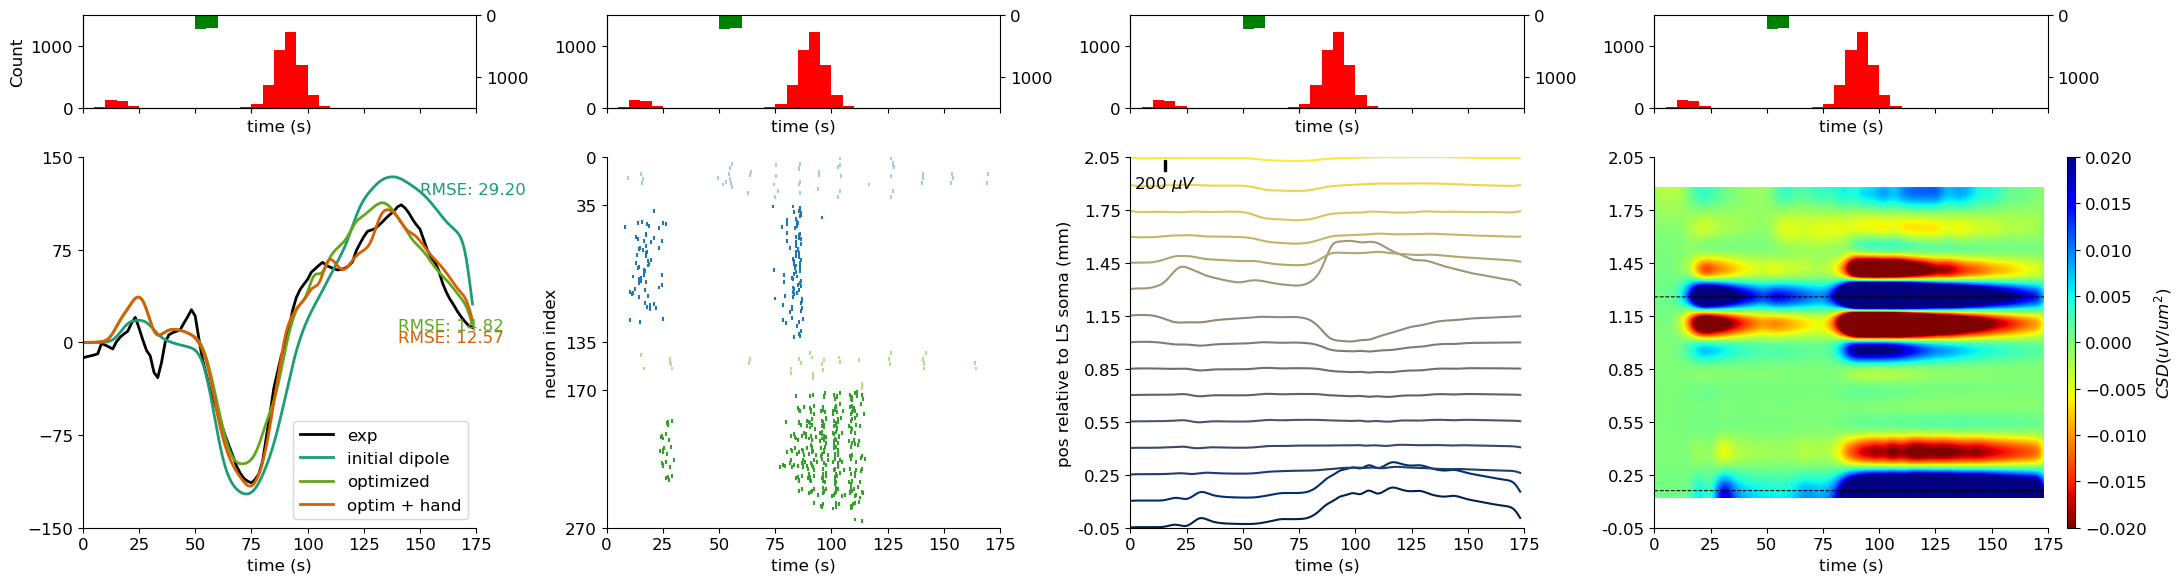

In [20]:
fig, ax = plt.subplots(2,4,figsize=(22,6), height_ratios=[0.25,1], sharex=True)

lfp = net_hand.rec_arrays['probe1'][0].voltages[0]
# drives
# proximal and distal histogram
spike_prox1 = np.array(net_hand.cell_response.spike_times_by_type['prox1']).reshape(-1,1)
spike_dist = np.array(net_hand.cell_response.spike_times_by_type['dist']).reshape(-1,1)
spike_prox2 = np.array(net_hand.cell_response.spike_times_by_type['prox2']).reshape(-1,1)

for i in range(4):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 1500])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()

ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='exp', color='k', linewidth=2)
ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1,0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized', color=col_lines[-1], linewidth=2)
ax[1,0].plot(hand_dpl.times,hand_dpl.data['agg'], label='optim + hand', color=col_lines[1], linewidth=2)
ax[1,0].text(150, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1,0].text(140, 0.5, 'RMSE: %.2f' % hand_rmse, fontsize=12, color=col_lines[1])
ax[1,0].text(140, 10, 'RMSE: %.2f' % _rmse(dpl_opt, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[-1])
ax[1,0].set_ylim([-150, 150])
ax[1,0].set_yticks([-150, -75, 0, 75, 150])
ax[1,0].legend(loc='lower right')

# spiking
I = np.array(net_hand.cell_response.spike_gids[0]) <270
gids = np.array(net_hand.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_hand.cell_response.spike_times).reshape(-1,)[I]
cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

colors = [assign_color(gid) for gid in gids]

ax[1,1].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1,1].set_ylabel('neuron index')
ax[1,1].set_xlim([0, 175])
ax[1,1].set_xticks(np.arange(0, 176, 25))

ax[1,1].set_xlabel('time (ms)')
ax[1,1].set_ylim([0, 270])
ax[1,1].set_yticks([0, 35, 135, 170, 270])
ax[1,1].invert_yaxis()


#ax[1,2].plot(net_hand.cell_response.times, lfp.T, color='k', alpha=0.5)
net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_lfp(ax=ax[1,2], show=False, voltage_offset=500, voltage_scalebar=200)
lfp_ticks = ax[1,2].get_yticks()
ax[1,2].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
ax[1,2].set_yticklabels(new_lim)
ax[1,2].set_ylabel('pos relative to L5 soma (mm)')
ax[1,2].set_ylim([lfp_ticks[0], lfp_ticks[-1]])

net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_csd(ax=ax[1,3], show=False, vmin=-.02, vmax=.02, sink='r')
ax[1,3].plot(net_hand.cell_response.times, np.ones(len(net_hand.cell_response.times),)*net_hand.pos_dict['L2_pyramidal'][0][2], color='k', linestyle='--', linewidth=.75)
ax[1,3].plot(net_hand.cell_response.times, np.ones(len(net_hand.cell_response.times),)*net_hand.pos_dict['L5_pyramidal'][0][2], color='k', linestyle='--', linewidth=.75)
csd_ticks = ax[1,3].get_yticks()
ax[1,3].set_yticks(np.linspace(csd_ticks[0], csd_ticks[-1], len(new_lim)))
ax[1,3].set_yticklabels(new_lim)
ax[1,3].set_ylabel('')
ax = ax.flatten()
for a in ax:
    a.set_xlabel('time (s)')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xticks(np.arange(0, 176, 25))
    a.set_xlim((0, 175))

fig.tight_layout()
fig.savefig(os.path.join(pathfig,'optim_hand_dpl.png'))
fig.savefig(os.path.join(pathfig,'optim_hand_dpl.pdf'))

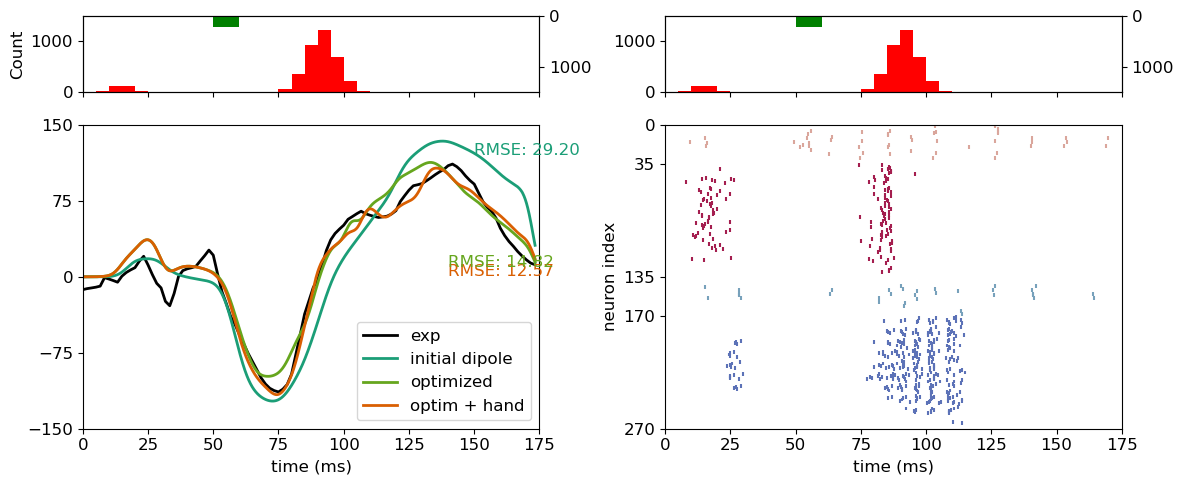

In [32]:
fig, ax = plt.subplots(2,2,figsize=(12,5), height_ratios=[0.25,1], sharex=True)

lfp = net_hand.rec_arrays['probe1'][0].voltages[0]
# drives
# proximal and distal histogram
spike_prox1 = np.array(net_hand.cell_response.spike_times_by_type['prox1']).reshape(-1,1)
spike_dist = np.array(net_hand.cell_response.spike_times_by_type['dist']).reshape(-1,1)
spike_prox2 = np.array(net_hand.cell_response.spike_times_by_type['prox2']).reshape(-1,1)

for i in range(2):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 1500])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()

ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='exp', color='k', linewidth=2)
ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='initial dipole', color=col_lines[0], linewidth=2)
ax[1,0].plot(dpl_opt.times,dpl_opt.data['agg'], label='optimized', color=col_lines[-1], linewidth=2)
ax[1,0].plot(hand_dpl.times,hand_dpl.data['agg'], label='optim + hand', color=col_lines[1], linewidth=2)
ax[1,0].text(150, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1,0].text(140, 0.5, 'RMSE: %.2f' % hand_rmse, fontsize=12, color=col_lines[1])
ax[1,0].text(140, 10, 'RMSE: %.2f' % _rmse(dpl_opt, exp_dpl,tstart=0,tstop=1000), fontsize=12, color=col_lines[-1])
ax[1,0].set_ylim([-150, 150])
ax[1,0].set_yticks([-150, -75, 0, 75, 150])
ax[1,0].legend(loc='lower right')

# spiking
I = np.array(net_hand.cell_response.spike_gids[0]) <270
gids = np.array(net_hand.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net_hand.cell_response.spike_times).reshape(-1,)[I]
cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

colors = [assign_color(gid) for gid in gids]

ax[1,1].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1,1].set_ylabel('neuron index')
ax[1,1].set_xlim([0, 175])
ax[1,1].set_xticks(np.arange(0, 176, 25))

ax[1,0].set_xlabel('time (ms)')

ax[1,1].set_xlabel('time (ms)')
ax[1,1].set_ylim([0, 270])
ax[1,1].set_yticks([0, 35, 135, 170, 270])
ax[1,1].invert_yaxis()


fig.tight_layout()
fig.savefig(os.path.join(pathfig,'optim_hand_dpl.png'))
fig.savefig(os.path.join(pathfig,'optim_hand_dpl.pdf'))

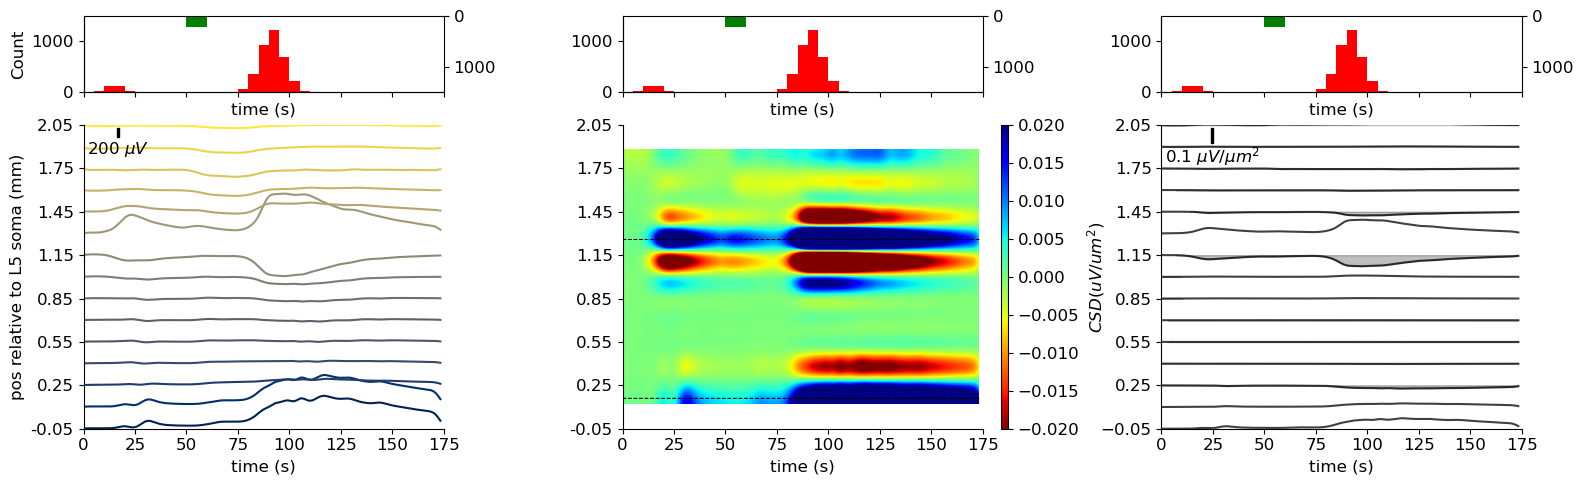

In [77]:
fig, ax = plt.subplots(2,3,figsize=(16,5), height_ratios=[0.25,1], sharex=True)

for i in range(3):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 1500])

    if i == 0:
        ax[0,i].set_ylabel('Count')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 1500])
    ax1tw.invert_yaxis()


#ax[1,2].plot(net_hand.cell_response.times, lfp.T, color='k', alpha=0.5)
net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_lfp(ax=ax[1,0], show=False, voltage_offset=500, voltage_scalebar=200)
lfp_ticks = ax[1,0].get_yticks()
ax[1,0].set_yticks(np.linspace(lfp_ticks[0], lfp_ticks[-1], len(new_lim)))
ax[1,0].set_yticklabels(new_lim)
ax[1,0].set_ylabel('pos relative to L5 soma (mm)')
ax[1,0].set_ylim([lfp_ticks[0], lfp_ticks[-1]])

net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len).plot_csd(ax=ax[1,1], show=False, vmin=-.02, vmax=.02, sink='r')
ax[1,1].plot(net_hand.cell_response.times, np.ones(len(net_hand.cell_response.times),)*net_hand.pos_dict['L2_pyramidal'][0][2], color='k', linestyle='--', linewidth=.75)
ax[1,1].plot(net_hand.cell_response.times, np.ones(len(net_hand.cell_response.times),)*net_hand.pos_dict['L5_pyramidal'][0][2], color='k', linestyle='--', linewidth=.75)
csd_ticks = ax[1,1].get_yticks()
ax[1,1].set_yticks(np.linspace(csd_ticks[0], csd_ticks[-1], len(new_lim)))
ax[1,1].set_yticklabels(new_lim)
ax[1,1].set_ylabel('')


lfp = net_hand.rec_arrays['probe1'][0].smooth(smooth_window_len)
lfp = lfp.voltages[0]

csd2d = calculate_csd2d(lfp, delta=delta)

n_offsets = csd2d.shape[0]
voltage_offset=0.1

c = -0.05
for i in range(csd2d.shape[0]):
    ax[1,2].plot(net_hand.cell_response.times, csd2d[i, :] + c, color='k', alpha=0.75)
    sink_idx = csd2d[i,:] < 0
    ax[1,2].fill_between(net_hand.cell_response.times[sink_idx], csd2d[i, sink_idx] + c, c, color='k', alpha=0.25)
    c += 0.15

ax[1,2].set_yticks(new_lim)
ax[1,2].set_ylim(new_lim[0], new_lim[-1])

from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
scalebar = AnchoredSizeBar(ax[1,2].transData, 1,
                                   f'{0.1} ' + r'$\mu V/\mu m^2$',
                                   'upper left',
                                   size_vertical=0.1,
                                   pad=0.1,
                                   color='black',
                                   label_top=False,
                                   frameon=False)   
ax[1,2].add_artist(scalebar)     
ax = ax.flatten()
for a in ax:
    a.set_xlabel('time (s)')
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xticks(np.arange(0, 176, 25))
    a.set_xlim((0, 175))


fig.savefig(os.path.join(pathfig,'supra_CSD_LFP.png'))
fig.savefig(os.path.join(pathfig,'supra_CSD_LFP.pdf'))

In [16]:
# run simulation longer to account for 50 ms bin

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    hand_dpl = simulate_dipole(net_hand, tstop=250, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

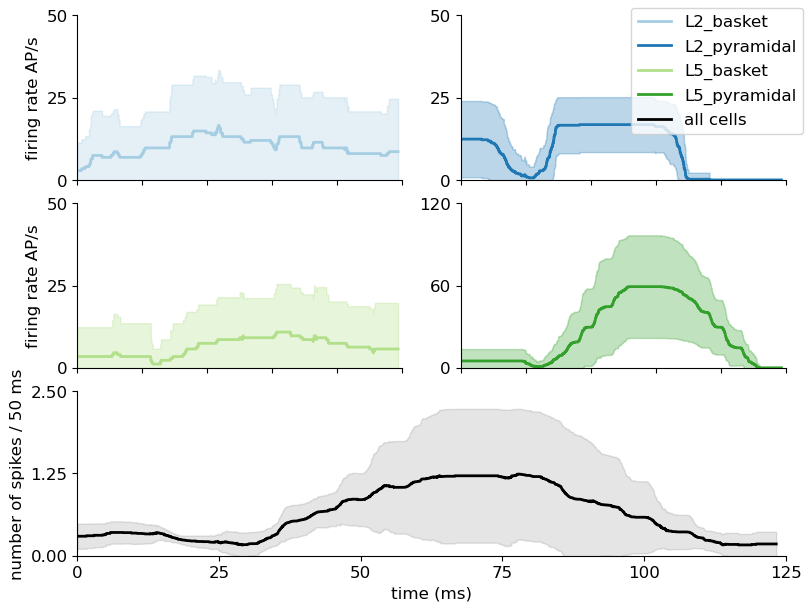

In [44]:
# firing rates

fig = plt.figure(figsize=(8,6), layout="constrained")
spec = fig.add_gridspec(3, 2)

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[0, 0])

ax1[1] = fig.add_subplot(spec[0, 1])

ax1[2] = fig.add_subplot(spec[1, 0])

ax1[3] = fig.add_subplot(spec[1, 1])

ax2 = fig.add_subplot(spec[2, :])


cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']

# 50 ms bin length
dt = np.diff(net_hand.cell_response.times)[0]
bin_ms = 50
bin_l = int(bin_ms / dt)  # bin length in number of time points
frates_all = np.zeros((4, len(net_hand.cell_response.times)-bin_l))

for i, cell_type in enumerate(cell_types):

    num_cells = net_hand.gid_ranges[cell_type][-1]-net_hand.gid_ranges[cell_type][0]+1
    frates_cell = np.zeros((num_cells, len(net_hand.cell_response.times)-bin_l))
    frates_cell5ms = np.zeros((num_cells, len(net_hand.cell_response.times)-int(5 / dt)))
    # Get the spike times for the current cell type
    spike_times_type = np.array(net_hand.cell_response.spike_times_by_type[cell_type][0])
    spike_times = np.array(net_hand.cell_response.spike_times[0])
    spike_gids = np.array(net_hand.cell_response.spike_gids[0])
    for ti, t in enumerate(net_hand.cell_response.times[:-bin_l]):
        spike_bool = (spike_times > t) & (spike_times < t + bin_ms)
        if (spike_bool).any():
            for g, gid in enumerate(net_hand.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])
        spike_bool = (spike_times > t) & (spike_times < t + 5)
        if (spike_bool).any():
            for g, gid in enumerate(net_hand.gid_ranges[cell_type]):
                frates_cell5ms[g, ti] = np.sum(gid == spike_gids[spike_bool])
    frates_all[i, :] = np.mean(frates_cell, axis=0)

    #ax0.plot(net_hand.cell_response.times[:-bin_l], frates_all[i, :], color=cm_neurons[i], linewidth=2)
    ax1[i].fill_between(net_hand.cell_response.times[:-bin_l], np.mean(frates_cell/bin_ms*1000, axis=0) - np.std(frates_cell/bin_ms*1000, axis=0), np.mean(frates_cell/bin_ms*1000, axis=0) + np.std(frates_cell/bin_ms*1000, axis=0), alpha=0.3, color=cm_neurons[i])
    ax1[i].plot(net_hand.cell_response.times[:-bin_l], np.mean(frates_cell/bin_ms*1000, axis=0), color=cm_neurons[i],label=cell_type, linewidth=2)
    ax1[i].set_ylim(bottom=0)
    ax1[i].set_xlim((0, 175))
    
ax2.plot(net_hand.cell_response.times[:-bin_l], np.mean(frates_all, axis=0), color='k', label='all cells', linewidth=2)
ax2.fill_between(net_hand.cell_response.times[:-bin_l], np.mean(frates_all, axis=0) - np.std(frates_all, axis=0), np.mean(frates_all, axis=0) + np.std(frates_all, axis=0), alpha=0.1, color='k')
ax2.set_ylabel('number of spikes / 50 ms')
    
#ax0.set_yticks(np.arange(0, 16, 5))
ax1[0].set_ylabel('firing rate AP/s')
ax1[2].set_ylabel('firing rate AP/s')


for i,a in enumerate(ax1):
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
    a.set_xticks(np.arange(0, 175, 25))
    a.set_xticklabels([])
    a.set_xlim((0, 125))

    if i == 3:
        a.set_ylim((0, 100))
        a.set_yticks(np.arange(0, 121, 60))
    else:
        a.set_ylim((0, 50))
        a.set_yticks(np.arange(0, 51, 25))


ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.set_xticks(np.arange(0, 126, 25))
ax2.set_xlim((0, 125))
ax2.set_xlabel('time (ms)')
ax2.set_ylim((0, 2.5))
ax2.set_yticks(np.arange(0, 2.6, 1.25))
# ax2.set_yticks(np.arange(0, 11, 5))

fig.legend()
fig.savefig(os.path.join(pathfig,'firing_rates.png'))
fig.savefig(os.path.join(pathfig,'firing_rates.pdf'))

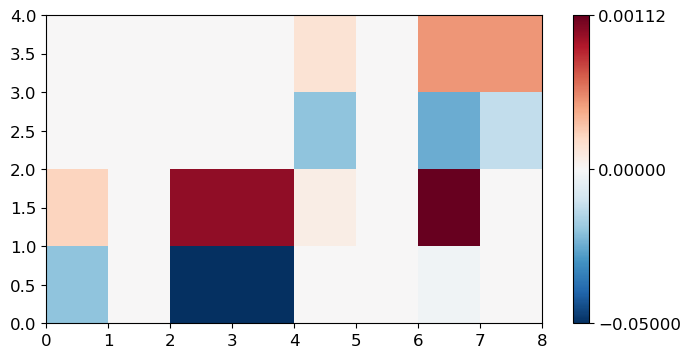

<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
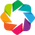

:Chord   [source,target]   (value)

In [80]:


hv.extension('bokeh')  # Required for interactive plotting

# Process connectivity data into edges DataFrame
edges = []
for source, targets in connectivity_data.items():
    for target, receptors in targets.items():
        # Sum all receptor values for connection strength
        weight = sum(receptors.values())  
        edges.append((source, target, weight))

# Create DataFrame with scaled weights
scaling_factor = 10  # Adjust this to control line thickness
df = pd.DataFrame(edges, columns=['source', 'target', 'value'])
df['value'] = df['value'] #* scaling_factor 

# Create nodes list for ordering
nodes = list(connectivity_data.keys())

# Create Chord plot
chord = hv.Chord((df, hv.Dataset(nodes, 'node'))).select(node=nodes)

# Customize plot appearance
chord.opts(
    opts.Chord(
        cmap=cmap,
        edge_cmap=cmap,
        edge_color=dim('source').str(),
        labels='node', 
        node_color=dim('node').str(),
        directed=True,
        #edge_line_width=dim('value'),
        width=800,
        height=800,
        #title='Cell Type Connectivity',
        node_size=25,
        label_text_font_size='12pt',
        tools=['hover'],
        inspection_policy='edges'
    )
)

# Display the plot
chord

# old

### Timing of drives

In [ ]:

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

def set_params_time(net, params):

    # Proximal 1
    
    net.add_evoked_drive('evprox1',
                         mu=params['evprox1_mu'],
                         sigma=params['evprox1_sigma'],
                         numspikes=1,
                         location='proximal',
                         weights_ampa=prox1_weights_ampa,
                         weights_nmda=prox1_weights_nmda,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    
    net.add_evoked_drive('evdist',
                         mu=params['evdist_mu'],
                         sigma=params['evdist_sigma'],
                         numspikes=int(np.round(params['evdist_num_spikes'])),
                         location='distal',
                         weights_ampa=dist_weights_ampa,
                         weights_nmda=dist_weights_nmda,
                         synaptic_delays=synaptic_delays_d, event_seed=544)
    
    net.add_evoked_drive('evprox2',
                        mu=params['evprox2_mu'],
                        sigma=params['evprox2_sigma'],
                        numspikes=int(np.round(params['evprox2_num_spikes'])),
                        location='proximal',
                        weights_ampa=prox2_weights_ampa,
                        weights_nmda=prox2_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay


constraints = dict({'evprox1_mu': (15, 21),
                'evprox1_sigma': (2., 5),

                'evdist_mu': (57, 62),
                'evdist_sigma': (2, 3),
                'evdist_num_spikes': (1, 2),

                'evprox2_mu': (94, 105),
                'evprox2_sigma': (8, 12),
                'evprox2_num_spikes': (1, 8)})

In [ ]:
net = human_ET_model()
optim_time = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params_time, solver='bayesian', obj_fun='dipole_rmse', max_iter=300)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim_time.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim_time.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim_time.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim_time.plot_convergence()

In [ ]:
opt_time_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)
opt_time_rmse

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
axes[0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].text(150,100, f'opt RMSE: {opt_time_rmse:.2f}', fontsize=12, color='tab:green')

optim_time.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

### Strength of drives

In [ ]:
prox1_mu = optim_time.net_.external_drives['evprox1']['dynamics']['mu'] 
prox1_sigma = optim_time.net_.external_drives['evprox1']['dynamics']['sigma']
prox1_num_spikes = optim_time.net_.external_drives['evprox1']['dynamics']['numspikes']
dist_mu = optim_time.net_.external_drives['evdist']['dynamics']['mu']
dist_sigma = optim_time.net_.external_drives['evdist']['dynamics']['sigma']         
dist_num_spikes = optim_time.net_.external_drives['evdist']['dynamics']['numspikes']
prox2_mu = optim_time.net_.external_drives['evprox2']['dynamics']['mu']
prox2_sigma = optim_time.net_.external_drives['evprox2']['dynamics']['sigma']
prox2_num_spikes = optim_time.net_.external_drives['evprox2']['dynamics']['numspikes']

In [ ]:
def set_params(net, params):

    # Proximal 1
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
    
    weights_ampa_p1 = {'L2_basket':
                       params['evprox1_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_ampa_L5_pyramidal']}
    weights_nmda_p1 = {'L2_basket':
                       params['evprox1_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_nmda_L5_pyramidal']}

    
    net.add_evoked_drive('evprox1',
                         mu=prox1_mu,
                         sigma=prox1_sigma,
                         numspikes=prox1_num_spikes,
                         location='proximal',
                         weights_ampa=weights_ampa_p1,
                         weights_nmda=weights_nmda_p1,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
    
    weights_ampa_d = {'L2_basket':
                       params['evdist_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_ampa_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_ampa_L5_pyramidal']}
    weights_nmda_d = {'L2_basket':
                       params['evdist_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_nmda_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_nmda_L5_pyramidal']}
    

    net.add_evoked_drive('evdist',
                         mu=dist_mu,
                        sigma=dist_sigma,
                        numspikes=dist_num_spikes,
                         location='distal',
                         weights_ampa=weights_ampa_d,
                         weights_nmda=weights_nmda_d,
                         synaptic_delays=synaptic_delays_d, event_seed=544)


    weights_ampa_p2 = {'L2_basket':
                       params['evprox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['evprox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('evprox2',
                        mu=prox2_mu,
                        sigma=prox2_sigma,
                        numspikes=prox2_num_spikes,
                        location='proximal',
                        weights_ampa=weights_ampa_p2,
                        weights_nmda=weights_nmda_p2,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay

# constrain such that L5 is driven more than L2
constraints = dict({'evprox1_ampa_L2_basket': (0.00001, .5),
                'evprox1_ampa_L2_pyramidal': (0.02, 1.),
                'evprox1_ampa_L5_basket': (0.00001, 0.5),
                'evprox1_ampa_L5_pyramidal': (0.00005, .1),

                'evprox1_nmda_L2_basket': (0.0001, 0.05),
                'evprox1_nmda_L2_pyramidal': (0.00005, 0.01),
                'evprox1_nmda_L5_basket': (0.0001, 0.05),
                'evprox1_nmda_L5_pyramidal': (0.0005, 0.1),

                'evdist_ampa_L2_basket': (0.0003, 0.01),
                'evdist_ampa_L2_pyramidal': (0.3, 1.),
                'evdist_ampa_L5_pyramidal': (0.3, 1.),
                'evdist_nmda_L2_basket': (9e-5, 1e-2),
                'evdist_nmda_L2_pyramidal': (0.01, 1.),
                'evdist_nmda_L5_pyramidal': (0.05, .6),

                'evprox2_ampa_L2_basket': (5e-3, 1e-2),
                'evprox2_ampa_L2_pyramidal': (0.001, .2),
                'evprox2_ampa_L5_basket': (2e-4, 1e-2),
                'evprox2_ampa_L5_pyramidal': (0.1, 1.),
                'evprox2_nmda_L2_basket': (9e-4, 1e-2),
                'evprox2_nmda_L2_pyramidal': (0.001, .5),
                'evprox2_nmda_L5_basket': (2e-4, 5e-2),
                'evprox2_nmda_L5_pyramidal': (0.1, .6)})
    


In [ ]:
net = human_ET_model()
optim = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params, solver='bayesian', obj_fun='dipole_rmse', max_iter=400)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

In [ ]:
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

In [ ]:
init_rmse = _rmse(init_dpl, exp_dpl, tstart=0, tstop=1000)
opt_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)


In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
axes[0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].text(150,100, f'opt RMSE: {opt_rmse:.2f}', fontsize=12, color='tab:green')

optim.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

In [ ]:
prox2_ampa = optim.net_.external_drives['evprox2']['weights_ampa']
prox2_nmda = optim.net_.external_drives['evprox2']['weights_nmda']

dist_ampa = optim.net_.external_drives['evdist']['weights_ampa']
dist_nmda = optim.net_.external_drives['evdist']['weights_nmda']

prox1_ampa = optim.net_.external_drives['evprox1']['weights_ampa']
prox1_nmda = optim.net_.external_drives['evprox1']['weights_nmda']

In [ ]:
fig = plt.figure(figsize=(8, 6), layout="constrained")
spec = fig.add_gridspec(3, 2)

ax0 = fig.add_subplot(spec[0, :])

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[1, 0])

ax1[1] = fig.add_subplot(spec[1, 1])

ax1[2] = fig.add_subplot(spec[2, 0])

ax1[3] = fig.add_subplot(spec[2, 1])


frates_all = np.zeros((4, len(optim.net_.cell_response.times)-smooth_window_len))

cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
for i, cell_type in enumerate(cell_types):

    frates_cell = np.zeros((max(optim.net_.gid_ranges[cell_type])+1, len(optim.net_.cell_response.times)-smooth_window_len))
    # Get the spike times for the current cell type
    spike_times_type = np.array(optim.net_.cell_response.spike_times_by_type[cell_type][0])
    spike_times = np.array(optim.net_.cell_response.spike_times[0])
    spike_gids = np.array(optim.net_.cell_response.spike_gids[0])
    for ti, t in enumerate(optim.net_.cell_response.times[:-smooth_window_len]):
        frates_all[i, ti] = np.sum((spike_times_type > t) & (spike_times_type < t + smooth_window_len))/smooth_window_len
        spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)
        if (spike_bool).any():
            for g, gid in enumerate(optim.net_.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])/smooth_window_len*1000
    ax0.plot(optim.net_.cell_response.times[:-smooth_window_len], frates_all[i, :])
    ax1[i].errorbar(optim.net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), np.std(frates_cell, axis=0), alpha=0.01, color=cols[i])
    ax1[i].plot(optim.net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), color=cols[i],label=cell_type)
    
ax0.set_ylabel('spikes')
ax1[0].set_ylabel('firing rate (Hz)')
ax1[2].set_ylabel('firing rate (Hz)')
ax1[2].set_xlabel('time (ms)')
ax1[3].set_xlabel('time (ms)')
fig.legend()


### Timing of drives

In [ ]:
opt_time_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)
opt_time_rmse

In [ ]:
prox1_mu = optim_time.net_.external_drives['evprox1']['dynamics']['mu'] 
prox1_sigma = optim_time.net_.external_drives['evprox1']['dynamics']['sigma']
prox1_num_spikes = optim_time.net_.external_drives['evprox1']['dynamics']['numspikes']
dist_mu = optim_time.net_.external_drives['evdist']['dynamics']['mu']
dist_sigma = optim_time.net_.external_drives['evdist']['dynamics']['sigma']         
dist_num_spikes = optim_time.net_.external_drives['evdist']['dynamics']['numspikes']
prox2_mu = optim_time.net_.external_drives['evprox2']['dynamics']['mu']
prox2_sigma = optim_time.net_.external_drives['evprox2']['dynamics']['sigma']
prox2_num_spikes = optim_time.net_.external_drives['evprox2']['dynamics']['numspikes']

## Round 2 optimize drives

In [ ]:
def set_params_round2(net, params):

    # Proximal 1
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
    
    weights_ampa_p1 = {'L2_basket':
                       params['evprox1_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_ampa_L5_pyramidal']}
    weights_nmda_p1 = {'L2_basket':
                       params['evprox1_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_nmda_L5_pyramidal']}

    
    net.add_evoked_drive('evprox1',
                         mu=prox1_mu,
                        sigma=prox1_sigma,
                         numspikes=prox1_num_spikes,
                         location='proximal',
                         weights_ampa=weights_ampa_p1,
                         weights_nmda=weights_nmda_p1,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
    
    weights_ampa_d = {'L2_basket':
                       params['evdist_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_ampa_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_ampa_L5_pyramidal']}
    weights_nmda_d = {'L2_basket':
                       params['evdist_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_nmda_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_nmda_L5_pyramidal']}
    

    net.add_evoked_drive('evdist',
                         mu=dist_mu,
                        sigma=dist_sigma,
                        numspikes=dist_num_spikes,
                         location='distal',
                         weights_ampa=weights_ampa_d,
                         weights_nmda=weights_nmda_d,
                         synaptic_delays=synaptic_delays_d, event_seed=544)


    weights_ampa_p2 = {'L2_basket':
                       params['evprox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['evprox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('evprox2',
                        mu=prox2_mu,
                        sigma=prox2_sigma,
                        numspikes=prox2_num_spikes,
                        location='proximal',
                        weights_ampa=weights_ampa_p2,
                        weights_nmda=weights_nmda_p2,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay

# constrain such that L5 is driven more than L2
constraints = dict({'evprox1_ampa_L2_basket': (0.001, 0.2),
                'evprox1_ampa_L2_pyramidal': (0.01, 0.4),
                'evprox1_ampa_L5_basket': (0.005, 0.2),
                'evprox1_ampa_L5_pyramidal': (0.01, .2),

                'evprox1_nmda_L2_basket': (0.001, 0.05),
                'evprox1_nmda_L2_pyramidal': (0.001, 0.01),
                'evprox1_nmda_L5_basket': (0.0001, 0.005),
                'evprox1_nmda_L5_pyramidal': (0.001, 0.01),

                'evdist_ampa_L2_basket': (0.003, 0.02),
                'evdist_ampa_L2_pyramidal': (0.3, .8),
                'evdist_ampa_L5_pyramidal': (0.3, .6),
                'evdist_nmda_L2_basket': (0.003, 0.02),
                'evdist_nmda_L2_pyramidal': (0.4, .7),
                'evdist_nmda_L5_pyramidal': (0.1, .4),

                'evprox2_ampa_L2_basket': (5e-3, 1e-1),
                'evprox2_ampa_L2_pyramidal': (0.1, .4),
                'evprox2_ampa_L5_basket': (2e-3, 1e-1),
                'evprox2_ampa_L5_pyramidal': (0.05, .2),
                'evprox2_nmda_L2_basket': (9e-3, 1e-2),
                'evprox2_nmda_L2_pyramidal': (0.03, .5),
                'evprox2_nmda_L5_basket': (2e-4, 4e-3),
                'evprox2_nmda_L5_pyramidal': (0.05, .2)
                })

In [ ]:
net = human_ET_model()
optim_round2 = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params_round2, solver='bayesian', obj_fun='dipole_rmse', max_iter=500)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim_round2.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl_round2 = simulate_dipole(optim_round2.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl_round2.scale(scale_factor)
opt_dpl_round2.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl_round2.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim_round2.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim_round2.plot_convergence()

In [ ]:
opt2_rmse = _rmse(opt_dpl_round2, exp_dpl, tstart=0, tstop=1000)
opt2_rmse

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
axes[0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl_round2.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].text(150,100, f'opt RMSE: {opt2_rmse:.2f}', fontsize=12, color='tab:green')

optim_round2.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl_round2.times,opt_dpl_round2.data['agg'],color='k', alpha=0.5)

In [ ]:
# import pickle
# with open('optim_time.pkl', 'rb') as file:
#         net_ = pickle.load(file)

In [ ]:
# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#     opt_dpl = simulate_dipole(net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
# opt_dpl.scale(scale_factor)
# opt_dpl.smooth(smooth_window_len)

In [ ]:
# opt_time_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)


In [ ]:
fig, axes = plt.subplots(2,2,figsize=(14, 5), sharex=True, height_ratios=[0.25,1])

optim.net_.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)
optim.net_.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)


exp_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:green')
axes[1,0].text(150,100, f'opt RMSE: {opt_time_rmse:.2f}', fontsize=12, color='tab:green')

optim.net_.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

fig.savefig(os.path.join(pathfig,'optimized_dpl_round2.png'))
fig.savefig(os.path.join(pathfig,'optimized_dpl_round2.svg'))

In [ ]:
smooth_window_len = 10


In [ ]:
fig = plt.figure(figsize=(8, 6), layout="constrained")
spec = fig.add_gridspec(4, 2)

ax0 = fig.add_subplot(spec[0, :])

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[1, 0])

ax1[1] = fig.add_subplot(spec[1, 1])

ax1[2] = fig.add_subplot(spec[2, 0])

ax1[3] = fig.add_subplot(spec[2, 1])

ax2 = fig.add_subplot(spec[3, :])


frates_type = np.zeros((4, len(net_.cell_response.times)-smooth_window_len))
frates_all = np.zeros((len(net_.cell_response.times)-smooth_window_len,))
cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
spike_times = np.array(net_.cell_response.spike_times[0])
spike_gids = np.array(net_.cell_response.spike_gids[0])


for i, cell_type in enumerate(cell_types):
    frates_cell = np.zeros((max(net_.gid_ranges[cell_type])+1, len(net_.cell_response.times)-smooth_window_len))
    for ti, t in enumerate(net_.cell_response.times[:-smooth_window_len]):
        spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)

        
        # Get the spike times for the current cell type
        spike_times_type = np.array(net_.cell_response.spike_times_by_type[cell_type][0])

        frates_type[i, ti] = np.sum((spike_times_type > t) & (spike_times_type < t + smooth_window_len))/smooth_window_len
        
        if (spike_bool).any():
            for g, gid in enumerate(net_.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])/smooth_window_len*1000
    ax0.plot(net_.cell_response.times[:-smooth_window_len], frates_type[i, :])
    ax1[i].errorbar(net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), np.std(frates_cell, axis=0), alpha=0.01, color=cols[i])
    ax1[i].plot(net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), color=cols[i],label=cell_type)

for ti, t in enumerate(net_.cell_response.times[:-smooth_window_len]):
    spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)
    frates_all[ti] = np.sum((spike_times > t) & (spike_times < t + smooth_window_len))/smooth_window_len
ax0.set_ylabel('spikes')
ax1[0].set_ylabel('firing rate (Hz)')
ax1[2].set_ylabel('firing rate (Hz)')
ax1[2].set_xlabel('time (ms)')
ax1[3].set_xlabel('time (ms)')
ax2.plot(net_.cell_response.times[:-smooth_window_len], frates_all, color='k', label='all cells')
fig.legend()

fig.savefig(os.path.join(pathfig,'firing_rates_optim_net_time.png'))
fig.savefig(os.path.join(pathfig,'firing_rates_optim_net_time.svg'))

In [ ]:
import pickle

with open('optim_time_new.pkl', 'wb') as file:
        pickle.dump(optim_time.net_, file)

with open('optim_drives_new.pkl', 'wb') as file:
        pickle.dump(optim.net_, file)

In [ ]:
# from hnn_core.dipole import _rmse

# _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)

In [ ]:
# fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# # plot original
# exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
# init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
# opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')

# optim_time.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
# ax2 = axes[1].twinx()
# ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)